In [90]:
import numpy as np
import pandas as pd

In [91]:
df = pd.read_csv(r"C:\Users\USER\Downloads\credit_card_churn_100_rows.csv")

In [92]:
df.head(2)

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1001,452,Spain,Female,36,0,20218.24,2,1,0,97275.89,1
1,1002,785,Spain,Male,43,4,107078.62,3,0,0,169997.37,1


In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df['Exited'].value_counts()

Exited
1    55
0    45
Name: count, dtype: int64

In [95]:
df['Geography'].value_counts()                    

Geography
Germany    40
France     35
Spain      25
Name: count, dtype: int64

In [96]:
df=pd.get_dummies(df,columns=['Geography','Gender'] , drop_first=True, dtype=int)

In [97]:
x =df.drop(columns=['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [98]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [99]:
xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)

In [100]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [101]:
model = Sequential()

model.add(Dense(3,activation = 'sigmoid',input_dim=12))
model.add(Dense(1,activation='sigmoid'))

C:\Users\USER\ml_env\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [102]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 3)              │            39 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43 (172.00 B)

 Trainable params: 43 (172.00 B)

 Non-trainable params: 0 (0.00 B)

In [103]:
model.compile(loss='binary_crossentropy',optimizer='Adam')

In [119]:
history = model.fit(xtrain_scaled,ytrain,epochs=10,validation_split=0.2)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - loss: 0.7822 - val_loss: 0.8660
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - loss: 0.7808 - val_loss: 0.8648
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - loss: 0.7797 - val_loss: 0.8636
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.7786 - val_loss: 0.8625
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.7772 - val_loss: 0.8613
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 0.7762 - val_loss: 0.8602
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.7749 - val_loss: 0.8591
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 0.7738 - val_loss: 0.8579
Epoch 9/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.7726 - val_loss: 0.8569
Epoch 10/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 0.7714 - val_loss: 0.8558


In [120]:
model.layers[0].get_weights()

[array([[-0.02534628,  0.52819234,  0.38352752],
        [-0.5280392 , -0.08743817,  0.35195768],
        [-0.49536657, -0.16369298, -0.0357549 ],
        [ 0.48746324, -0.42590305,  0.23219119],
        [ 0.00730584, -0.04035985, -0.42457175],
        [ 0.07930775, -0.6082306 , -0.46427807],
        [ 0.3929221 ,  0.5202493 , -0.0543534 ],
        [-0.42775166,  0.4483884 ,  0.45793512],
        [-0.3562506 ,  0.23622206, -0.17545149],
        [-0.44167408,  0.04185124, -0.11285764],
        [ 0.26242208, -0.44611484,  0.2545484 ],
        [ 0.64339334, -0.53262025,  0.10569587]], dtype=float32),
 array([-0.06032259, -0.06099823,  0.06243946], dtype=float32)]

In [121]:
ylog=model.predict(xtest_scaled)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


In [122]:
ypred=np.where(ylog>0.5,1,0)

In [123]:
from sklearn.metrics import accuracy_score

In [124]:
accuracy_score(ytest,ypred)

0.55

In [118]:
import matplotlib.pyplot as plt 

In [125]:
history.history

{'loss': [0.7821640968322754,
  0.7808464765548706,
  0.7797150611877441,
  0.7785542607307434,
  0.777191162109375,
  0.7762336730957031,
  0.7748690843582153,
  0.7737703323364258,
  0.772577702999115,
  0.7714042067527771],
 'val_loss': [0.8659887313842773,
  0.8648108839988708,
  0.8636333346366882,
  0.8624801635742188,
  0.8613443970680237,
  0.8601920008659363,
  0.8590555191040039,
  0.8579402565956116,
  0.8568501472473145,
  0.85578453540802]}

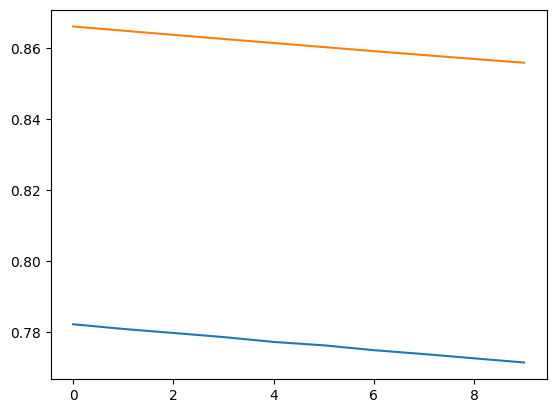

In [131]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])